In [1]:
# importing basic libraries for modeling and plots
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import scipy.stats as stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

In [2]:
# loading the admissions dataset
df = pd.read_csv('Admission_Prediction.csv')
print(df.head(3))

   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0           1        337          118                  4  4.5  4.5  9.65   
1           2        324          107                  4  4.0  4.5  8.87   
2           3        316          104                  3  3.0  3.5  8.00   

   Research  Chance of Admit  Year  \
0         1             0.92  2022   
1         1             0.76  2022   
2         1             0.72  2022   

                              University_Name region  
0    Indian Institute of Technology Kharagpur   East  
1  National Institute of Technology Karnataka  South  
2                          Gujarat University   West  


In [3]:
# selecting predictor columns and target column
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['Chance of Admit']

# adding constant term for linear regression
X_const = sm.add_constant(X)

In [4]:
# fitting the multiple linear regression model
model = sm.OLS(y, X_const).fit()

# printing simple model summary numbers
print('r-squared:', round(model.rsquared, 4))
print('adjusted r-squared:', round(model.rsquared_adj, 4))
print('\ncoefficients:')
print(model.params.round(4))

r-squared: 0.2208
adjusted r-squared: 0.2153

coefficients:
const               -0.5316
GRE Score            0.0015
TOEFL Score          0.0025
University Rating    0.0023
SOP                  0.0141
LOR                  0.0127
CGPA                 0.0458
Research             0.0380
dtype: float64


In [5]:
# checking multicollinearity using variance inflation factor (vif)
vif_table = pd.DataFrame()
vif_table['feature'] = features
vif_table['vif'] = [variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])]

print('vif results:')
print(vif_table.round(2))
# vif values below 5 mean no serious multicollinearity

vif results:
             feature   vif
0          GRE Score  1.15
1        TOEFL Score  1.13
2  University Rating  1.19
3                SOP  1.21
4                LOR  1.21
5               CGPA  1.26
6           Research  1.10


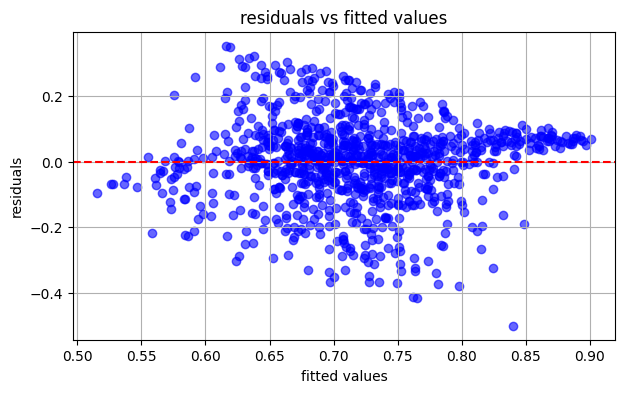

In [6]:
# getting fitted values and residuals
fitted = model.fittedvalues
residuals = model.resid

# plotting residuals vs fitted values to check linearity and zero mean
plt.figure(figsize=(7, 4))
plt.scatter(fitted, residuals, color='blue', alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.title('residuals vs fitted values')
plt.xlabel('fitted values')
plt.ylabel('residuals')
plt.grid(True)
plt.show()

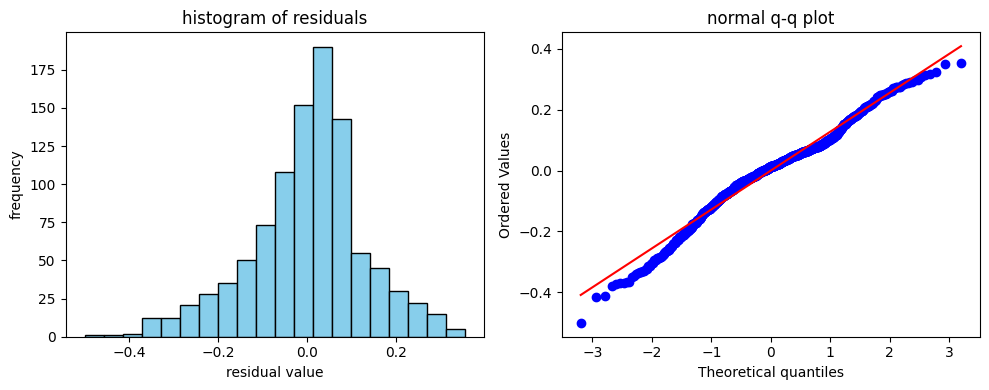

In [7]:
# checking normality of residuals with histogram and qq plot
plt.figure(figsize=(10, 4))

# histogram of residuals
plt.subplot(1, 2, 1)
plt.hist(residuals, bins=20, color='skyblue', edgecolor='black')
plt.title('histogram of residuals')
plt.xlabel('residual value')
plt.ylabel('frequency')

# normal qq plot
plt.subplot(1, 2, 2)
stats.probplot(residuals, dist='norm', plot=plt)
plt.title('normal q-q plot')

plt.tight_layout()
plt.show()

breusch-pagan test results:
lm test statistic: 15.5179
p-value: 0.0299


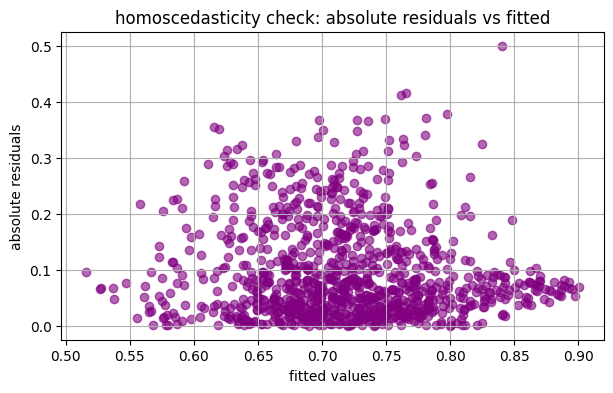

In [8]:
# testing homoscedasticity using the breusch-pagan test
bp_test = het_breuschpagan(residuals, model.model.exog)
lm_statistic = bp_test[0]
p_value = bp_test[1]

print('breusch-pagan test results:')
print('lm test statistic:', round(lm_statistic, 4))
print('p-value:', round(p_value, 4))

# plotting absolute residuals vs fitted to easily spot any variance funnel
plt.figure(figsize=(7, 4))
plt.scatter(fitted, np.abs(residuals), color='purple', alpha=0.6)
plt.title('homoscedasticity check: absolute residuals vs fitted')
plt.xlabel('fitted values')
plt.ylabel('absolute residuals')
plt.grid(True)
plt.show()

model performance metrics:
root mean squared error (rmse): 0.1287
mean of residuals: 0.0


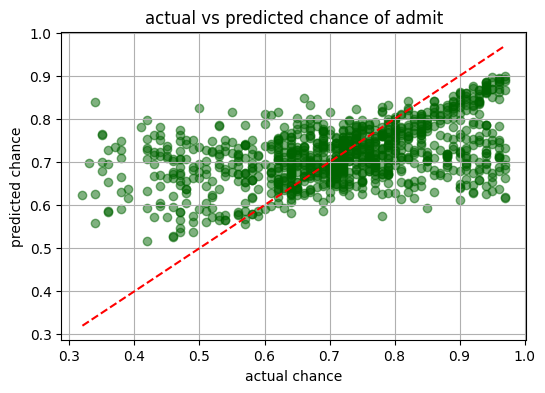

In [9]:
# checking overall accuracy with rmse and actual vs predicted plot
actual = y
predicted = fitted
rmse = np.sqrt(np.mean((actual - predicted) ** 2))

print('model performance metrics:')
print('root mean squared error (rmse):', round(rmse, 4))
print('mean of residuals:', round(np.mean(residuals), 6))

plt.figure(figsize=(6, 4))
plt.scatter(actual, predicted, color='darkgreen', alpha=0.5)
plt.plot([actual.min(), actual.max()], [actual.min(), actual.max()], color='red', linestyle='--')
plt.title('actual vs predicted chance of admit')
plt.xlabel('actual chance')
plt.ylabel('predicted chance')
plt.grid(True)
plt.show()

In [10]:
# simple conclusion on model assumptions
print('diagnostic summary:')
print('1. multicollinearity: all vif values are below 5, so no severe multicollinearity.')
print('2. residual normality: residuals roughly follow a normal distribution.')
print('3. homoscedasticity: residual spread is examined via scatter plot and breusch-pagan test.')
print('4. accuracy: low rmse indicates predictions are close to actual admission chance.')

diagnostic summary:
1. multicollinearity: all vif values are below 5, so no severe multicollinearity.
2. residual normality: residuals roughly follow a normal distribution.
3. homoscedasticity: residual spread is examined via scatter plot and breusch-pagan test.
4. accuracy: low rmse indicates predictions are close to actual admission chance.
